# Flight Delay Predictor
Predict if a flight will arrive more than 15 minutes late, using only information known **before** departure.


**Data:** nycflights13 (all 2013 flights from NYC airports), installed with pip. If it fails, a small synthetic sample is made.

**Important:** departure delay is NOT used as a feature because that would be data leakage (we would not know it before the flight leaves).

In [1]:
!pip install -q nycflights13 scikit-learn pandas matplotlib

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

try:
    from nycflights13 import flights
    df = flights.copy()
    print("real data loaded:", df.shape)
except Exception as e:
    print("could not load nycflights13, using synthetic data:", e)
    n = 30000
    df = pd.DataFrame({
        "year": 2013,
        "month": np.random.randint(1, 13, n),
        "day": np.random.randint(1, 28, n),
        "sched_dep_time": np.random.randint(5, 23, n) * 100,
        "carrier": np.random.choice(["AA", "UA", "DL", "B6", "EV"], n),
        "origin": np.random.choice(["JFK", "LGA", "EWR"], n),
        "dest": np.random.choice(["ATL", "LAX", "ORD", "MIA", "BOS", "DFW"], n),
        "distance": np.random.randint(200, 2500, n),
    })
    chance = 0.12 + (df["sched_dep_time"] / 100 - 5) * 0.012 + (df["month"].isin([6, 7, 12])) * 0.07
    df["arr_delay"] = np.where(np.random.rand(n) < chance, np.random.randint(16, 200, n), np.random.randint(-30, 15, n))

df.head()

/usr/local/lib/python3.13/dist-packages/nycflights13/__init__.py:2: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_filename as _rf


real data loaded: (336776, 19)


,year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour
0,2013,1,1,517.0,515,2.0,830.0,819,11.0,UA,1545,N14228,EWR,IAH,227.0,1400,5,15,2013-01-01T10:00:00Z
1,2013,1,1,533.0,529,4.0,850.0,830,20.0,UA,1714,N24211,LGA,IAH,227.0,1416,5,29,2013-01-01T10:00:00Z
2,2013,1,1,542.0,540,2.0,923.0,850,33.0,AA,1141,N619AA,JFK,MIA,160.0,1089,5,40,2013-01-01T10:00:00Z
3,2013,1,1,544.0,545,-1.0,1004.0,1022,-18.0,B6,725,N804JB,JFK,BQN,183.0,1576,5,45,2013-01-01T10:00:00Z
4,2013,1,1,554.0,600,-6.0,812.0,837,-25.0,DL,461,N668DN,LGA,ATL,116.0,762,6,0,2013-01-01T11:00:00Z


In [3]:
df = df.dropna(subset=["arr_delay", "sched_dep_time", "distance"])
df["late"] = (df["arr_delay"] > 15).astype(int)
df["dep_hour"] = df["sched_dep_time"] // 100
df["date"] = pd.to_datetime(dict(year=df["year"], month=df["month"], day=df["day"]))
df["dayofweek"] = df["date"].dt.dayofweek

print("rows:", len(df))
print("share of late flights:", round(df["late"].mean() * 100, 1), "%")

print(df.groupby("dep_hour")["late"].mean().round(3))

rows: 327346
share of late flights: 23.7 %
dep_hour
5     0.099
6     0.113
7     0.114
8     0.157
9     0.164
10    0.177
11    0.178
12    0.199
13    0.229
14    0.257
15    0.295
16    0.294
17    0.326
18    0.326
19    0.341
20    0.347
21    0.366
22    0.331
23    0.296
Name: late, dtype: float64


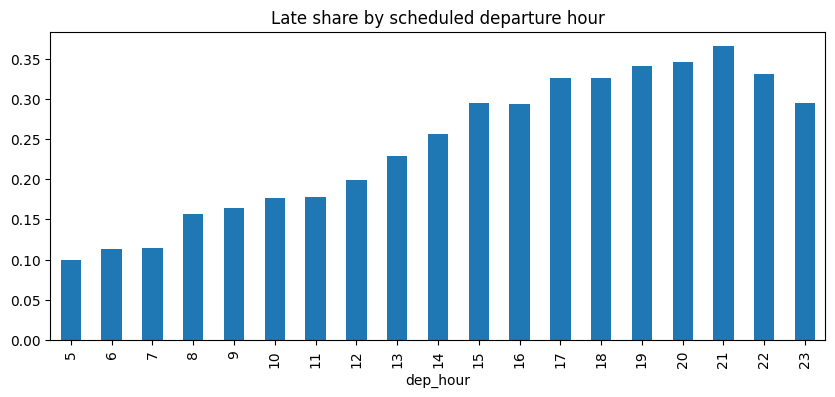

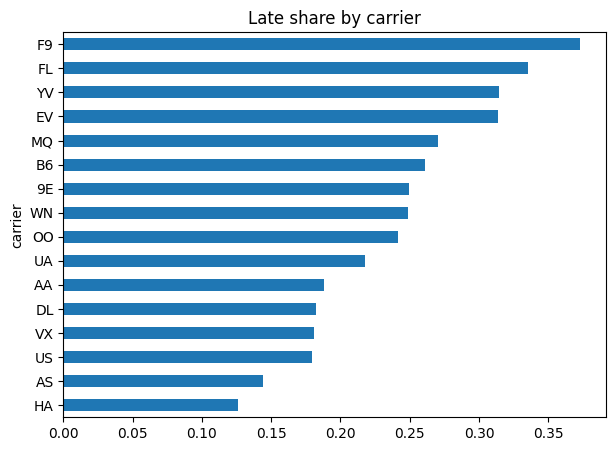

In [4]:
df.groupby("dep_hour")["late"].mean().plot(kind="bar", figsize=(10,4), title="Late share by scheduled departure hour")
plt.show()

df.groupby("carrier")["late"].mean().sort_values().plot(kind="barh", figsize=(7,5), title="Late share by carrier")
plt.show()

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report, confusion_matrix

if len(df) > 120000:
    df = df.sample(120000, random_state=42)

cat_cols = ["carrier", "origin", "dest"]
num_cols = ["month", "dayofweek", "dep_hour", "distance"]

enc = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
X = df[cat_cols + num_cols].copy()
X[cat_cols] = enc.fit_transform(X[cat_cols])
y = df["late"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

majority = y_train.mode()[0]
print("Baseline (always predict majority) accuracy:", round(accuracy_score(y_test, [majority]*len(y_test)), 4))

Baseline (always predict majority) accuracy: 0.7616


In [6]:
lr = LogisticRegression(max_iter=500)
lr.fit(X_train, y_train)
lr_prob = lr.predict_proba(X_test)[:, 1]
print("Logistic Regression  accuracy:", round(accuracy_score(y_test, lr_prob > 0.5), 4), " AUC:", round(roc_auc_score(y_test, lr_prob), 4))

gb = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1, random_state=42)
gb.fit(X_train, y_train)
gb_prob = gb.predict_proba(X_test)[:, 1]
print("Gradient Boosting    accuracy:", round(accuracy_score(y_test, gb_prob > 0.5), 4), " AUC:", round(roc_auc_score(y_test, gb_prob), 4))

Logistic Regression  accuracy: 0.7616  AUC: 0.6382
Gradient Boosting    accuracy: 0.7763  AUC: 0.7216


In [7]:
for cut in [0.5, 0.3, 0.2]:
    pred = (gb_prob > cut).astype(int)
    print("Threshold", cut)
    print(classification_report(y_test, pred, digits=3))
    print(confusion_matrix(y_test, pred))
    print()

Threshold 0.5
              precision    recall  f1-score   support

           0      0.788     0.967     0.868     18278
           1      0.613     0.167     0.263      5722

    accuracy                          0.776     24000
   macro avg      0.701     0.567     0.566     24000
weighted avg      0.746     0.776     0.724     24000

[[17675   603]
 [ 4765   957]]

Threshold 0.3
              precision    recall  f1-score   support

           0      0.836     0.806     0.820     18278
           1      0.444     0.495     0.468      5722

    accuracy                          0.732     24000
   macro avg      0.640     0.650     0.644     24000
weighted avg      0.743     0.732     0.736     24000

[[14723  3555]
 [ 2887  2835]]

Threshold 0.2
              precision    recall  f1-score   support

           0      0.876     0.566     0.687     18278
           1      0.349     0.745     0.476      5722

    accuracy                          0.608     24000
   macro avg      0.61

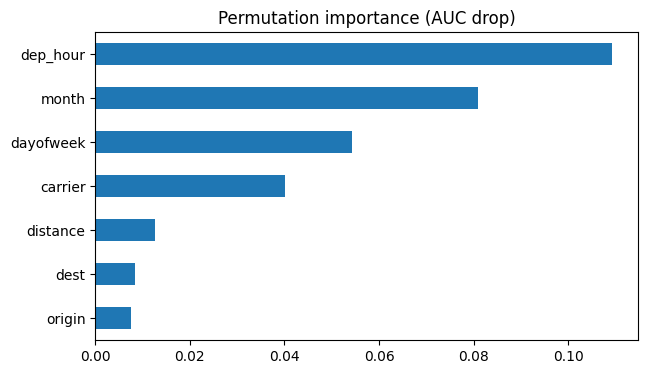

origin       0.0077
dest         0.0083
distance     0.0127
carrier      0.0401
dayofweek    0.0543
month        0.0809
dep_hour     0.1092
dtype: float64


In [8]:
from sklearn.inspection import permutation_importance

sample = X_test.sample(min(5000, len(X_test)), random_state=1)
sample_y = y_test.loc[sample.index]
result = permutation_importance(gb, sample, sample_y, n_repeats=3, random_state=42, scoring="roc_auc")
imp = pd.Series(result.importances_mean, index=X_test.columns).sort_values()
imp.plot(kind="barh", figsize=(7,4), title="Permutation importance (AUC drop)")
plt.show()
print(imp.round(4))

In [ ]:

# ============================================================
# UNIVERSAL COLAB PROJECT AUTO-SAVE
# Structure: Parent Folder / Notebook Name / All Project Files
# ============================================================

import os
import json
import shutil
from pathlib import Path
from google.colab import auth, _message
from googleapiclient.discovery import build
from googleapiclient.http import MediaFileUpload
from google.auth import default

# 1. DESTINATION GOOGLE DRIVE FOLDER
PARENT_FOLDER_ID = "1RJ_KbIui8TyupB2kr3c-N93lt2OE0nAk"

# 2. AUTHENTICATE
auth.authenticate_user()
credentials, _ = default()
drive = build("drive", "v3", credentials=credentials)

# 3. DETECT CURRENT NOTEBOOK
notebook_data = _message.blocking_request("get_ipynb")

if "ipynb" in notebook_data:
    notebook_data = notebook_data["ipynb"]

project_name = (
    notebook_data.get("metadata", {})
    .get("colab", {})
    .get("name", "")
)

if not project_name:
    project_name = input("Enter your Colab notebook name (e.g. RAG): ").strip()

project_name = Path(project_name).stem

if not project_name:
    raise ValueError("Project name is missing.")

print("Project detected:", project_name)

# 4. FIND OR CREATE PROJECT FOLDER
query = (
    f"'{PARENT_FOLDER_ID}' in parents "
    f"and name = '{project_name}' "
    "and mimeType = 'application/vnd.google-apps.folder' "
    "and trashed = false"
)

results = drive.files().list(
    q=query,
    fields="files(id,name)",
    supportsAllDrives=True,
    includeItemsFromAllDrives=True
).execute()

if results.get("files"):
    PROJECT_FOLDER_ID = results["files"][0]["id"]
else:
    folder = drive.files().create(
        body={
            "name": project_name,
            "mimeType": "application/vnd.google-apps.folder",
            "parents": [PARENT_FOLDER_ID]
        },
        fields="id"
    ).execute()

    PROJECT_FOLDER_ID = folder["id"]

# 5. UPLOAD FILES WITHOUT ZIP
SKIP_DIRS = {
    "drive", "sample_data", ".config",
    ".cache", "__pycache__"
}

uploaded = 0
failed = []

def find_existing_file(name, parent_id):
    q = (
        f"'{parent_id}' in parents "
        f"and name = '{name}' "
        "and trashed = false"
    )
    found = drive.files().list(
        q=q,
        fields="files(id)",
        supportsAllDrives=True,
        includeItemsFromAllDrives=True
    ).execute()
    return found.get("files", [])

def upload_file(local_path, parent_id):
    global uploaded

    filename = os.path.basename(local_path)

    metadata = {
        "name": filename,
        "parents": [parent_id]
    }

    media = MediaFileUpload(
        local_path,
        resumable=True
    )

    existing = find_existing_file(filename, parent_id)

    if existing:
        drive.files().update(
            fileId=existing[0]["id"],
            media_body=media,
            supportsAllDrives=True
        ).execute()
    else:
        drive.files().create(
            body=metadata,
            media_body=media,
            fields="id",
            supportsAllDrives=True
        ).execute()

    uploaded += 1
    print("Saved:", filename)

def upload_directory(local_dir, drive_parent_id):
    for item in os.scandir(local_dir):

        if item.is_dir(follow_symlinks=False):

            if item.name in SKIP_DIRS:
                continue

            existing = find_existing_file(
                item.name, drive_parent_id
            )

            if existing:
                subfolder_id = existing[0]["id"]
            else:
                result = drive.files().create(
                    body={
                        "name": item.name,
                        "mimeType": "application/vnd.google-apps.folder",
                        "parents": [drive_parent_id]
                    },
                    fields="id",
                    supportsAllDrives=True
                ).execute()
                subfolder_id = result["id"]

            upload_directory(item.path, subfolder_id)

        elif item.is_file(follow_symlinks=False):
            try:
                upload_file(item.path, drive_parent_id)
            except Exception as error:
                failed.append((item.name, str(error)))
                print("Upload failed:", item.name, error)

# 6. SAVE EXECUTED NOTEBOOK
notebook_path = f"/content/{project_name}.ipynb"

with open(notebook_path, "w", encoding="utf-8") as f:
    json.dump(notebook_data, f, ensure_ascii=False, indent=2)

# 7. UPLOAD PROJECT FILES
upload_directory("/content", PROJECT_FOLDER_ID)

# 8. FINAL REPORT
print("\n======================================")
print("PROJECT BACKUP COMPLETED")
print("======================================")
print("Project:", project_name)
print("Uploaded files:", uploaded)
print("Failed files:", len(failed))
print(
    "Folder:",
    f"https://drive.google.com/drive/folders/{PROJECT_FOLDER_ID}"
)

if failed:
    print("\nFailed uploads:")
    for name, error in failed:
        print(name, error)